In [400]:
# Get via points 
import numpy as np
from os import listdir
import pandas as pd

subject = 's028'

folder_path = 'D:\\MTP_task\\cam_data\\' + subject + '\\'
files = sorted(listdir(folder_path)) # sort files in ascending order
kinematics_ME = [0]*(int(len(files))) # initialize list to store ME dataframes
j,k = 0,0
for i in range(len(files)):
    print("Reading file ME: " + files[i])
    kinematics_ME[i] = pd.read_excel(folder_path + files[i])
    k += 1

kinematics_ME_all = pd.concat(kinematics_ME, ignore_index=True)
kinematics_ME_all = kinematics_ME_all.ffill()

Reading file ME: s028_block_01_MTPTask.xlsx
Reading file ME: s028_block_03_MTPTask.xlsx
Reading file ME: s028_block_05_MTPTask.xlsx
Reading file ME: s028_block_07_MTPTask.xlsx
Reading file ME: s028_block_09_MTPTask.xlsx
Reading file ME: s028_block_11_MTPTask.xlsx


# Helping Function 

In [401]:
from scipy.signal import medfilt

def despike_with_median(x, k=5, thresh=3.5):
    x = np.asarray(x)
    base = medfilt(x, kernel_size=k)          # พื้นฐานแบบ median
    resid = x - base

    # robust scale ด้วย MAD
    mad = np.median(np.abs(resid - np.median(resid))) + 1e-12
    z = resid / (1.4826 * mad)                # approx z-score แบบ robust

    spike_idx = np.abs(z) > thresh            # จุดที่นับว่าเป็น spike
    y = x.copy()
    y[spike_idx] = base[spike_idx]            # แทนค่า spike ด้วย median พื้นฐาน
    return y, spike_idx

def lowpass_filter(x, fs=30, fc=5, order=4):
    from scipy.signal import butter, filtfilt
    nyq = 0.5 * fs
    normal_cutoff = fc / nyq
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    y = filtfilt(b, a, x)
    return y


def smooth_signal(x, k=5):
    lowpass_x = lowpass_filter(x, fs=30, fc=2, order=4)
    # return lowpass_x
    return medfilt(lowpass_x, kernel_size=k)


In [402]:
kinematics_ME_all['Wrist_cz_smoothed'] = smooth_signal(kinematics_ME_all['Wirst_cz'].copy(), k=41)
kinematics_ME_all['Elbow_cz_smoothed'] = smooth_signal(kinematics_ME_all['Elbow_cz'].copy(), k=41)

In [403]:
IMU_data = kinematics_ME_all['IMU'].values

In [404]:
IMU_data[0].split(',')

['2.5220', '-36.5850', '14.8470', '5.3310', '-38.7090', '19.9630']

In [405]:
IMU_array = np.zeros((len(IMU_data), 6))
for i in range(len(IMU_data)):
    if len(IMU_data[i].split(',')) != 6:
        IMU_array[i] = IMU_array[i-1]
    else:
        for j in range(6):
            IMU_array[i, j] = float(IMU_data[i].split(',')[j])


In [406]:
IMU_filter = np.zeros_like(IMU_array)

for i in range(6):
    IMU_filter[:,i] = lowpass_filter(IMU_array[:,i], fs=30, fc=2, order=4)

# Convert angular velocity from deg/s to rad/s
# rad/s = deg/s * pi / 180
IMU_filter_rad_s = np.deg2rad(IMU_filter)


In [407]:
kinematics_ME_all.info()

<class 'pandas.DataFrame'>
RangeIndex: 36000 entries, 0 to 35999
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   time (s)           36000 non-null  float64
 1   Should_cx          36000 non-null  float64
 2   Should_cy          36000 non-null  float64
 3   Should_cz          36000 non-null  float64
 4   Elbow_cx           36000 non-null  float64
 5   Elbow_cy           36000 non-null  float64
 6   Elbow_cz           36000 non-null  float64
 7   Wirst_cx           36000 non-null  float64
 8   Wirst_cy           36000 non-null  float64
 9   Wirst_cz           36000 non-null  float64
 10  Elbow_u            36000 non-null  int64  
 11  Elbow_v            36000 non-null  int64  
 12  Wirst_u            36000 non-null  int64  
 13  Wirst_v            36000 non-null  int64  
 14  stimulus           36000 non-null  str    
 15  trial              36000 non-null  int64  
 16  IMU                36000 non-null

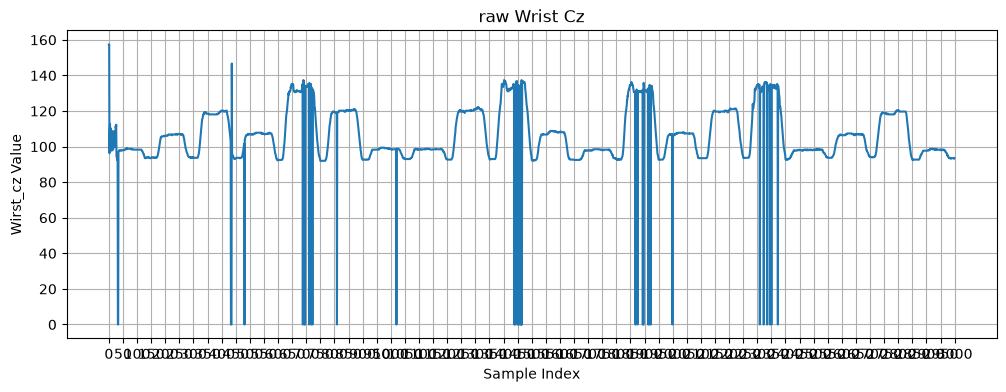

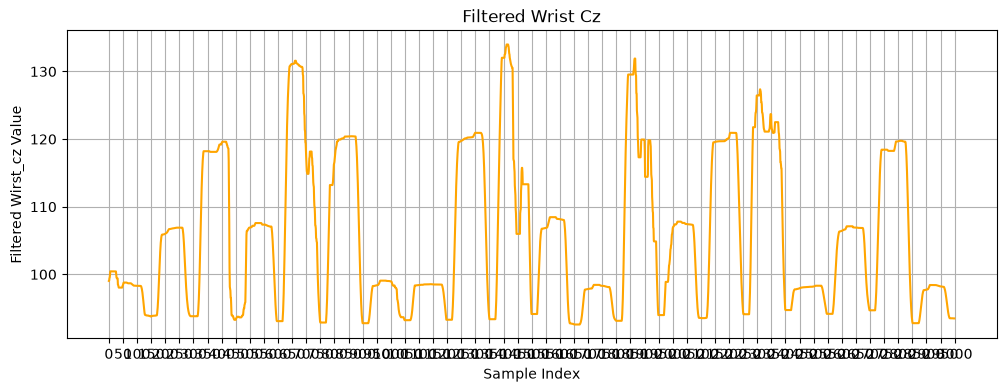

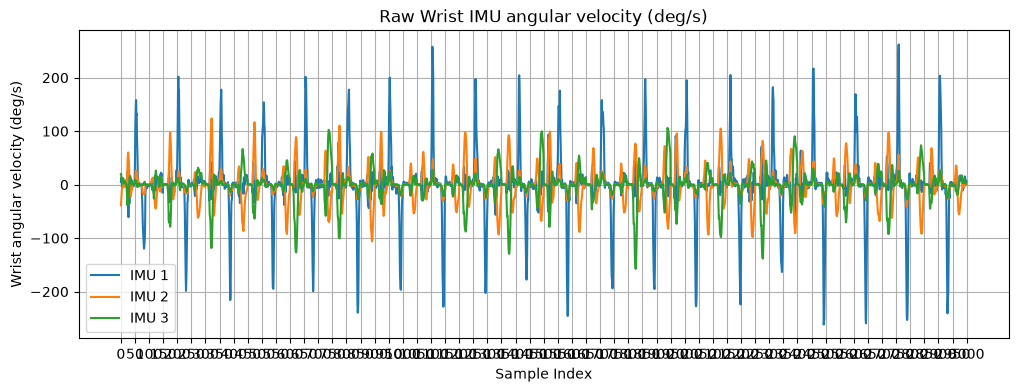

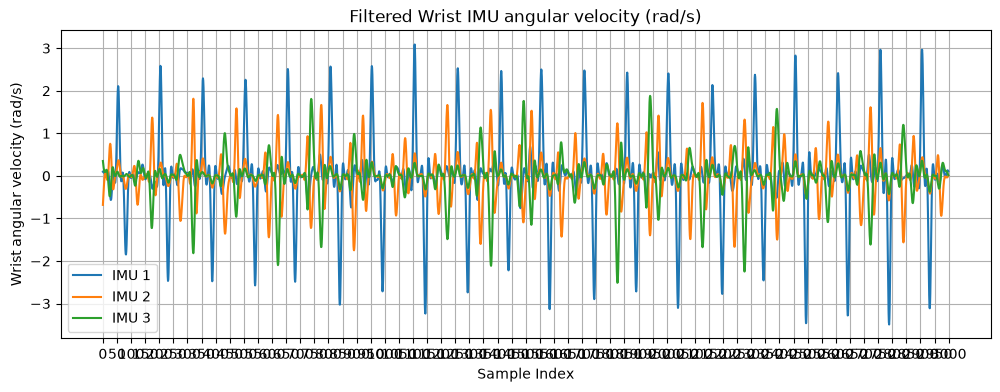

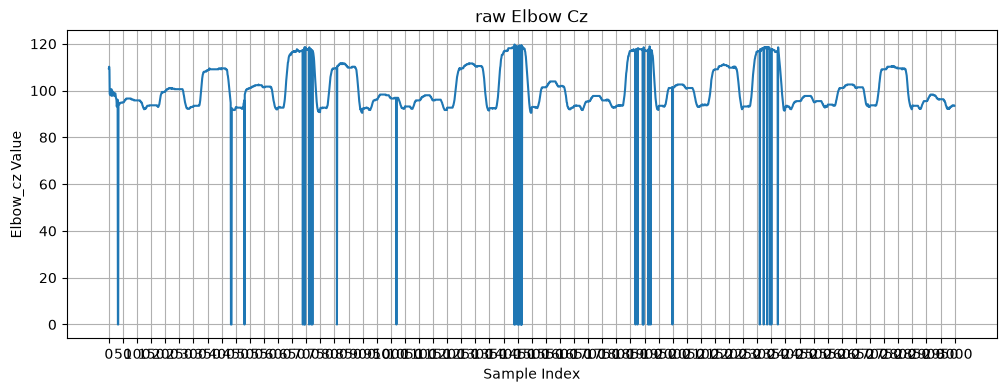

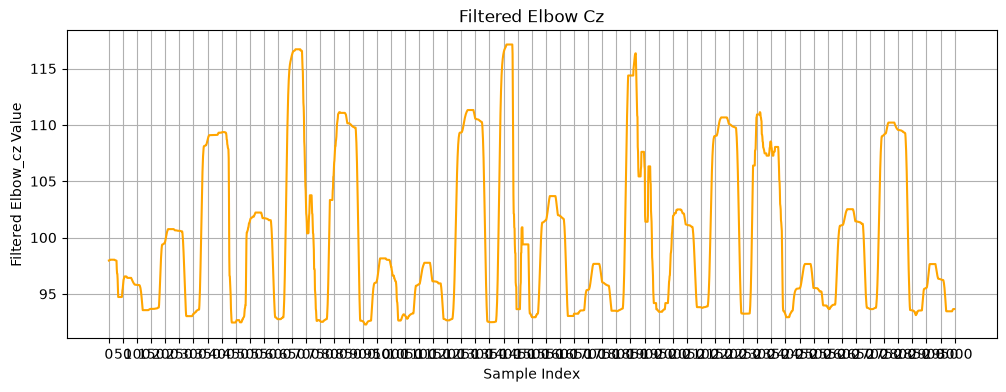

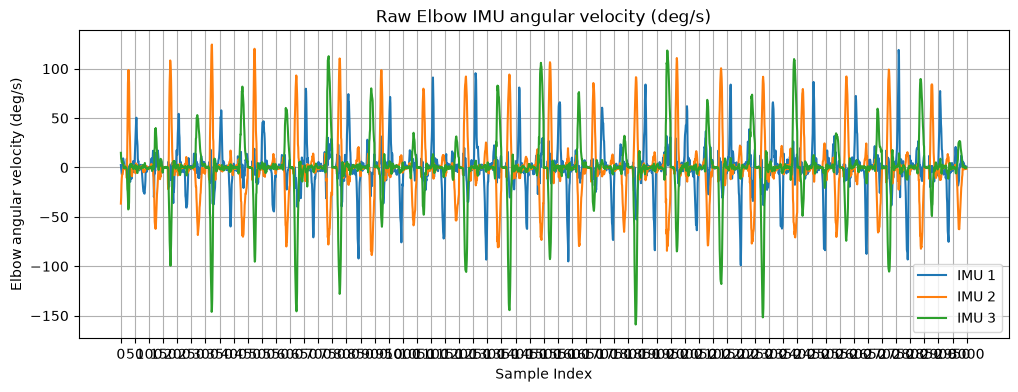

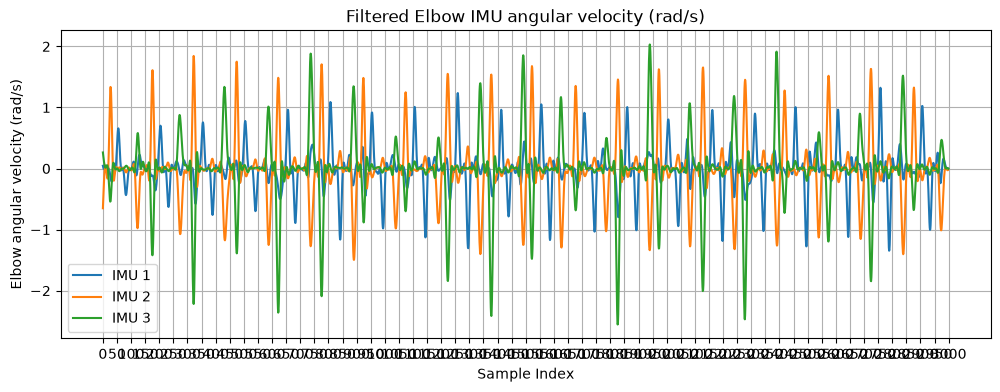

In [408]:
import matplotlib.pyplot as plt

plot_range = (0, 3000)

plt.figure(figsize=(12, 4))
plt.plot(kinematics_ME_all['Wirst_cz'][plot_range[0]:plot_range[1]].values)
plt.title('raw Wrist Cz')
plt.xlabel('Sample Index')
# adjust x axis's grid values to be every 50 samples
plt.xticks(np.arange(0, plot_range[1]-plot_range[0]+1, 50))
plt.ylabel('Wirst_cz Value')
plt.grid(True)
plt.show()

plt.figure(figsize=(12, 4))
plt.plot(kinematics_ME_all['Wrist_cz_smoothed'][plot_range[0]:plot_range[1]].values, color='orange')
plt.title('Filtered Wrist Cz')
plt.xticks(np.arange(0, plot_range[1]-plot_range[0]+1, 50))
plt.xlabel('Sample Index')
plt.ylabel('Filtered Wirst_cz Value')
plt.grid(True)
plt.show()

plt.figure(figsize=(12, 4))
plt.plot(IMU_array[plot_range[0]:plot_range[1], 3], label='IMU 1')
plt.plot(IMU_array[plot_range[0]:plot_range[1], 4], label='IMU 2')
plt.plot(IMU_array[plot_range[0]:plot_range[1], 5], label='IMU 3')
plt.xlabel('Sample Index')
plt.xticks(np.arange(0, plot_range[1]-plot_range[0]+1, 50))
plt.ylabel('Wrist angular velocity (deg/s)')
plt.title('Raw Wrist IMU angular velocity (deg/s)')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(12, 4))
plt.plot(IMU_filter_rad_s[plot_range[0]:plot_range[1], 3], label='IMU 1')
plt.plot(IMU_filter_rad_s[plot_range[0]:plot_range[1], 4], label='IMU 2')
plt.plot(IMU_filter_rad_s[plot_range[0]:plot_range[1], 5], label='IMU 3')
plt.xlabel('Sample Index')
plt.xticks(np.arange(0, plot_range[1]-plot_range[0]+1, 50))
plt.ylabel('Wrist angular velocity (rad/s)')
plt.title('Filtered Wrist IMU angular velocity (rad/s)')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(12, 4))
plt.plot(kinematics_ME_all['Elbow_cz'][plot_range[0]:plot_range[1]].values)
plt.title('raw Elbow Cz')
plt.xlabel('Sample Index')
# adjust x axis's grid values to be every 50 samples
plt.xticks(np.arange(0, plot_range[1]-plot_range[0]+1, 50))
plt.ylabel('Elbow_cz Value')
plt.grid(True)
plt.show()

plt.figure(figsize=(12, 4))
plt.plot(kinematics_ME_all['Elbow_cz_smoothed'][plot_range[0]:plot_range[1]].values, color='orange')
plt.title('Filtered Elbow Cz')
plt.xticks(np.arange(0, plot_range[1]-plot_range[0]+1, 50))
plt.xlabel('Sample Index')
plt.ylabel('Filtered Elbow_cz Value')
plt.grid(True)
plt.show()

plt.figure(figsize=(12, 4))
plt.plot(IMU_array[plot_range[0]:plot_range[1], 0], label='IMU 1')
plt.plot(IMU_array[plot_range[0]:plot_range[1], 1], label='IMU 2')
plt.plot(IMU_array[plot_range[0]:plot_range[1], 2], label='IMU 3')
plt.xlabel('Sample Index')
plt.xticks(np.arange(0, plot_range[1]-plot_range[0]+1, 50))
plt.ylabel('Elbow angular velocity (deg/s)')
plt.title('Raw Elbow IMU angular velocity (deg/s)')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(12, 4))
plt.plot(IMU_filter_rad_s[plot_range[0]:plot_range[1], 0], label='IMU 1')
plt.plot(IMU_filter_rad_s[plot_range[0]:plot_range[1], 1], label='IMU 2')
plt.plot(IMU_filter_rad_s[plot_range[0]:plot_range[1], 2], label='IMU 3')
plt.xlabel('Sample Index')
plt.xticks(np.arange(0, plot_range[1]-plot_range[0]+1, 50))
plt.ylabel('Elbow angular velocity (rad/s)')
plt.title('Filtered Elbow IMU angular velocity (rad/s)')
plt.legend()
plt.grid(True)
plt.show()

### SI-unit conversion
- Kinect linear velocities are converted from **cm/s to m/s** using `0.01`.
- IMU angular velocities are converted from **deg/s to rad/s** using `π/180`.
- The trajectory outlier thresholds therefore operate on linear velocity in **m/s**.


In [409]:
rows_per_trial = 150 # (30 Hz for 5 seconds)
kinematics_ME_all['trial'] = [
    i+1 for i in range(len(kinematics_ME_all) // 150) for _ in range(rows_per_trial)
]

traject_shoulder_label = {}  # dict[stimulus] -> (n_trials, n_timepoints, 3) 
traject_elbow_label = {}  # dict[stimulus] -> (n_trials, n_timepoints, 3)
traject_wirst_label = {}  # dict[stimulus] -> (n_trials, n_timepoints, 3)
traject_IMU_label = {}  # dict[stimulus] -> (n_trials, n_timepoints, 6)

# ============================================================
# Unit conversion constants
# ============================================================
CM_TO_M = 0.01                  # cm -> m
DEG_TO_RAD = np.pi / 180.0      # deg -> rad

def lowpass_filter(x, fs=30, fc=5, order=4):
    from scipy.signal import butter, filtfilt
    nyq = 0.5 * fs
    normal_cutoff = fc / nyq
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    y = filtfilt(b, a, x)
    return y


def smooth_signal(x, k=5):
    lowpass_x = lowpass_filter(x, fs=30, fc=2, order=4)
    # return lowpass_x
    return medfilt(lowpass_x, kernel_size=k)


for stim_name, stim_df in kinematics_ME_all.groupby('stimulus', sort=False):
    vshoulder_trials = []
    velbow_trials = []
    vwirst_trials = []
    IMU_trials = []
    print(f"Processing stimulus: {stim_name}")

    for trial_id, trial_df in stim_df.groupby('trial', sort=False): 
        t = trial_df['time (s)'].to_numpy()
        print(f"  Processing trial: {trial_id}")


        IMU_data = trial_df['IMU'].values

        IMU_array = np.zeros((len(IMU_data), 6))
        IMU_array_transfrom = np.zeros((len(IMU_data), 6))

        # for i in range(len(IMU_data)):
        #     if len(IMU_data[i]) != 6:
        #         IMU_array[i] = IMU_data[i-1]
        #     else:
        #         for j in range(6):
        #             IMU_array[i, j] = float(IMU_data[i][j])
                    
                    
        for i in range(len(IMU_data)):
            if len(IMU_data[i].split(',')) != 6:
                IMU_array[i] = IMU_array[i-1]
            else:
                for j in range(6):
                    IMU_array[i, j] = float(IMU_data[i].split(',')[j])

        IMU_array_transfrom[:,0] = -IMU_array[:,0] # imu_elbow_x_dps
        IMU_array_transfrom[:,1] = IMU_array[:,2] # imu_elbow_z_dps
        IMU_array_transfrom[:,2] = -IMU_array[:,1] # imu_elbow_y_dps
        IMU_array_transfrom[:,3] = -IMU_array[:,3] # imu_wrist_x_dps
        IMU_array_transfrom[:,4] = IMU_array[:,5] # imu_wrist_z_dps
        IMU_array_transfrom[:,5] = -IMU_array[:,4] # imu_wrist_y_dps

        IMU_filter = np.zeros_like(IMU_array_transfrom)
        for i in range(6):
            IMU_filter[:, i] = lowpass_filter(IMU_array_transfrom[:, i], fc=2, fs=30, order=4)

        # Convert filtered angular velocity from deg/s to rad/s
        # rad/s = deg/s * pi / 180
        IMU_filter_rad_s = IMU_filter * DEG_TO_RAD


        # print(trial_df['Should_cx'].to_numpy().shape)
        Should_cx = smooth_signal(trial_df['Should_cx'].to_numpy(), k=41)
        Should_cy = smooth_signal(trial_df['Should_cy'].to_numpy(), k=41)
        Should_cz = smooth_signal(trial_df['Should_cz'].to_numpy(), k=41)

        Elbow_cx = smooth_signal(trial_df['Elbow_cx'].to_numpy(), k=41)
        Elbow_cy = smooth_signal(trial_df['Elbow_cy'].to_numpy(), k=41)
        Elbow_cz = smooth_signal(trial_df['Elbow_cz'].to_numpy(), k=41)

        Wirst_cx = smooth_signal(trial_df['Wirst_cx'].to_numpy(), k=41) 
        Wirst_cy = smooth_signal(trial_df['Wirst_cy'].to_numpy(), k=41)
        Wirst_cz = smooth_signal(trial_df['Wirst_cz'].to_numpy(), k=41)

        
        # If sampling is uneven, np.gradient(x, t) handles it correctly.
        # The Kinect coordinates are in cm, so the derivatives below are initially cm/s.
        Should_vx = np.gradient(Should_cx, t)
        Should_vy = np.gradient(Should_cy, t)
        Should_vz = np.gradient(Should_cz, t)
        Elbow_vx = np.gradient(Elbow_cx, t)
        Elbow_vy = np.gradient(Elbow_cy, t)
        Elbow_vz = np.gradient(Elbow_cz, t)
        Wirst_vx = np.gradient(Wirst_cx, t)
        Wirst_vy = np.gradient(Wirst_cy, t)
        Wirst_vz = np.gradient(Wirst_cz, t)

        # Convert linear velocity from cm/s to m/s
        Should_vx *= CM_TO_M
        Should_vy *= CM_TO_M
        Should_vz *= CM_TO_M
        Elbow_vx *= CM_TO_M
        Elbow_vy *= CM_TO_M
        Elbow_vz *= CM_TO_M
        Wirst_vx *= CM_TO_M
        Wirst_vy *= CM_TO_M
        Wirst_vz *= CM_TO_M

        vshoulder_trials.append(np.stack([Should_vx, Should_vy, Should_vz], axis=1))
        velbow_trials.append(np.stack([Elbow_vx, Elbow_vy, Elbow_vz], axis=1))
        vwirst_trials.append(np.stack([Wirst_vx, Wirst_vy, Wirst_vz], axis=1))

        # Store IMU angular velocity in rad/s
        IMU_trials.append(IMU_filter_rad_s)


    traject_shoulder_label[stim_name] = np.stack(vshoulder_trials, axis=0) 
    traject_elbow_label[stim_name] = np.stack(velbow_trials, axis=0)  
    traject_wirst_label[stim_name] = np.stack(vwirst_trials, axis=0) 
    traject_IMU_label[stim_name] = np.stack(IMU_trials, axis=0) 

# Quick check
for key, arr in traject_shoulder_label.items():
    print(f"{key}: velocity shape {arr.shape}")

Processing stimulus: Number 4
  Processing trial: 1
  Processing trial: 7
  Processing trial: 8
  Processing trial: 12
  Processing trial: 17
  Processing trial: 20
  Processing trial: 24
  Processing trial: 25
  Processing trial: 36
  Processing trial: 40
  Processing trial: 46
  Processing trial: 47
  Processing trial: 52
  Processing trial: 53
  Processing trial: 61
  Processing trial: 69
  Processing trial: 72
  Processing trial: 74
  Processing trial: 75
  Processing trial: 80
  Processing trial: 81
  Processing trial: 83
  Processing trial: 84
  Processing trial: 91
  Processing trial: 94
  Processing trial: 100
  Processing trial: 101
  Processing trial: 102
  Processing trial: 103
  Processing trial: 114
  Processing trial: 121
  Processing trial: 122
  Processing trial: 127
  Processing trial: 134
  Processing trial: 141
  Processing trial: 142
  Processing trial: 149
  Processing trial: 152
  Processing trial: 154
  Processing trial: 160
  Processing trial: 165
  Processing t

In [410]:
traject_IMU_label['Number 1'].shape

(60, 150, 6)

## Velocity-threshold trajectory outlier rejection

This section replaces the SCP-style early-start / bell-shape rejection with a **robust velocity-outlier rule**.

For each trial and each joint (wrist, elbow, shoulder), the 3-D tangential velocity is computed as:

$$V_t(t)=\sqrt{V_x(t)^2+V_y(t)^2+V_z(t)^2}$$

and the trial peak speed is:

$$V_{peak}=\max_t V_t(t).$$

For each joint, one subject-specific threshold is estimated from all ME trials using a robust median/MAD rule:

$$T=\operatorname{median}(V_{peak})+k\,(1.4826\,MAD),$$

with $k=3$ by default. A trial is rejected if the peak tangential velocity of **any** joint exceeds its joint-specific threshold.

This is a data-driven outlier QC rule; it is not the exact rejection rule used in the SCP paper.

**file:///C:/Users/user/Downloads/913874.pdf.pdf (Uncertainty Machine — User’s Manual)**


In [411]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# Robust velocity-threshold trajectory outlier rejection
# ============================================================
# One notebook run is assumed to correspond to one subject.
# Thresholds are therefore estimated separately for this subject
# and separately for wrist, elbow, and shoulder.
# Linear trajectory velocities are in m/s at this stage.

MAD_K = 3.0


def tangential_velocity(velocity_xyz):
    """Compute 3-D tangential speed from [Vx, Vy, Vz]."""
    velocity_xyz = np.asarray(velocity_xyz, dtype=float)
    return np.sqrt(np.sum(velocity_xyz ** 2, axis=-1))


def robust_velocity_threshold(peak_velocities, k=3.0):
    """
    Threshold = median + k * 1.4826 * MAD.

    A small IQR fallback is used only if MAD is exactly zero,
    which can happen when many peak velocities are identical.
    """
    x = np.asarray(peak_velocities, dtype=float)
    x = x[np.isfinite(x)]
    if len(x) == 0:
        raise ValueError('No finite peak velocities available to estimate threshold.')

    med = np.median(x)
    mad = np.median(np.abs(x - med))
    robust_sigma = 1.4826 * mad

    if robust_sigma > 0:
        threshold = med + k * robust_sigma
        method = f'median + {k:g} × 1.4826 × MAD'
    else:
        q1, q3 = np.percentile(x, [25, 75])
        iqr = q3 - q1
        threshold = q3 + 1.5 * iqr if iqr > 0 else np.nextafter(med, np.inf)
        method = 'Q3 + 1.5 × IQR (MAD was zero)'

    return {
        'threshold': float(threshold),
        'median': float(med),
        'mad': float(mad),
        'robust_sigma': float(robust_sigma),
        'method': method,
    }


def collect_peak_velocities(trajectory_dict):
    """
    trajectory_dict: dict[stimulus] -> (n_trials, n_timepoints, 3)

    Returns
    -------
    peaks : np.ndarray
        Peak tangential velocity pooled across all classes.
    records : list[dict]
        Class/trial mapping for each peak.
    """
    peaks = []
    records = []

    for class_name, trials in trajectory_dict.items():
        trials = np.asarray(trials, dtype=float)
        for trial_index, trial in enumerate(trials):
            vt = tangential_velocity(trial)
            peak_v = float(np.nanmax(vt))
            peaks.append(peak_v)
            records.append({
                'class_name': class_name,
                'trial_index': trial_index,
                'peak_velocity': peak_v,
                'vt': vt,
            })

    return np.asarray(peaks, dtype=float), records


# ------------------------------------------------------------
# 1) Compute peak tangential velocity for each joint/trial
# ------------------------------------------------------------
wrist_peaks, wrist_records = collect_peak_velocities(traject_wirst_label)
elbow_peaks, elbow_records = collect_peak_velocities(traject_elbow_label)
shoulder_peaks, shoulder_records = collect_peak_velocities(traject_shoulder_label)

# ------------------------------------------------------------
# 2) Estimate one robust threshold per joint for this subject
# ------------------------------------------------------------
wrist_stats = robust_velocity_threshold(wrist_peaks, k=MAD_K)
elbow_stats = robust_velocity_threshold(elbow_peaks, k=MAD_K)
shoulder_stats = robust_velocity_threshold(shoulder_peaks, k=MAD_K)

velocity_thresholds = {
    'wrist': wrist_stats,
    'elbow': elbow_stats,
    'shoulder': shoulder_stats,
}

print('=========================================')
print('Robust velocity thresholds (m/s)')
print('=========================================')
for joint, stats in velocity_thresholds.items():
    print(
        f"{joint.capitalize():8s}: threshold={stats['threshold']:.3f} | "
        f"median={stats['median']:.3f} | MAD={stats['mad']:.3f} | "
        f"{stats['method']}"
    )

# ------------------------------------------------------------
# 3) Build a lookup table for each class/trial
# ------------------------------------------------------------
def make_peak_lookup(records):
    return {
        (r['class_name'], r['trial_index']): r['peak_velocity']
        for r in records
    }

wrist_lookup = make_peak_lookup(wrist_records)
elbow_lookup = make_peak_lookup(elbow_records)
shoulder_lookup = make_peak_lookup(shoulder_records)

# ------------------------------------------------------------
# 4) Reject a trial if ANY joint exceeds its own threshold
# ------------------------------------------------------------
reject_label_index = []
velocity_qc_results = []

for class_name in traject_wirst_label.keys():
    n_trials = traject_wirst_label[class_name].shape[0]

    for trial_index in range(n_trials):
        key = (class_name, trial_index)

        wrist_peak = wrist_lookup[key]
        elbow_peak = elbow_lookup[key]
        shoulder_peak = shoulder_lookup[key]

        reject_wrist = wrist_peak > wrist_stats['threshold']
        reject_elbow = elbow_peak > elbow_stats['threshold']
        reject_shoulder = shoulder_peak > shoulder_stats['threshold']

        reject = reject_wrist or reject_elbow or reject_shoulder

        reasons = []
        if reject_wrist:
            reasons.append(
                f"wrist {wrist_peak:.2f}>{wrist_stats['threshold']:.2f}"
            )
        if reject_elbow:
            reasons.append(
                f"elbow {elbow_peak:.2f}>{elbow_stats['threshold']:.2f}"
            )
        if reject_shoulder:
            reasons.append(
                f"shoulder {shoulder_peak:.2f}>{shoulder_stats['threshold']:.2f}"
            )

        if reject:
            reject_label_index.append(key)

        velocity_qc_results.append({
            'class_name': class_name,
            'trial_index': trial_index,
            'wrist_peak': wrist_peak,
            'elbow_peak': elbow_peak,
            'shoulder_peak': shoulder_peak,
            'reject_wrist': reject_wrist,
            'reject_elbow': reject_elbow,
            'reject_shoulder': reject_shoulder,
            'reject': reject,
            'reasons': reasons,
        })

        status = 'REJECT' if reject else 'ACCEPT'
        reason_text = '; '.join(reasons) if reasons else 'within thresholds'
        print(
            f"{status:6s} | {class_name:10s} | trial {trial_index:3d} | "
            f"W={wrist_peak:7.3f} m/s, E={elbow_peak:7.3f} m/s, S={shoulder_peak:7.3f} m/s | "
            f"{reason_text}"
        )

print('\n=========================================')
print('Velocity-outlier rejection summary')
print('=========================================')
print('Total trials   :', len(velocity_qc_results))
print('Rejected trials:', len(reject_label_index))
if len(velocity_qc_results) > 0:
    print('Rejected (%)   :', 100 * len(reject_label_index) / len(velocity_qc_results))
print('reject_label_index =', reject_label_index)


Robust velocity thresholds (m/s)
Wrist   : threshold=1.419 | median=0.838 | MAD=0.131 | median + 3 × 1.4826 × MAD
Elbow   : threshold=0.954 | median=0.664 | MAD=0.065 | median + 3 × 1.4826 × MAD
Shoulder: threshold=0.258 | median=0.133 | MAD=0.028 | median + 3 × 1.4826 × MAD
REJECT | Number 4   | trial   0 | W=  1.068 m/s, E=  0.720 m/s, S=  0.493 m/s | shoulder 0.49>0.26
ACCEPT | Number 4   | trial   1 | W=  0.588 m/s, E=  0.490 m/s, S=  0.118 m/s | within thresholds
ACCEPT | Number 4   | trial   2 | W=  0.612 m/s, E=  0.535 m/s, S=  0.163 m/s | within thresholds
ACCEPT | Number 4   | trial   3 | W=  0.597 m/s, E=  0.547 m/s, S=  0.170 m/s | within thresholds
ACCEPT | Number 4   | trial   4 | W=  0.521 m/s, E=  0.414 m/s, S=  0.089 m/s | within thresholds
ACCEPT | Number 4   | trial   5 | W=  0.648 m/s, E=  0.584 m/s, S=  0.141 m/s | within thresholds
ACCEPT | Number 4   | trial   6 | W=  0.604 m/s, E=  0.569 m/s, S=  0.149 m/s | within thresholds
ACCEPT | Number 4   | trial   7 | W= 

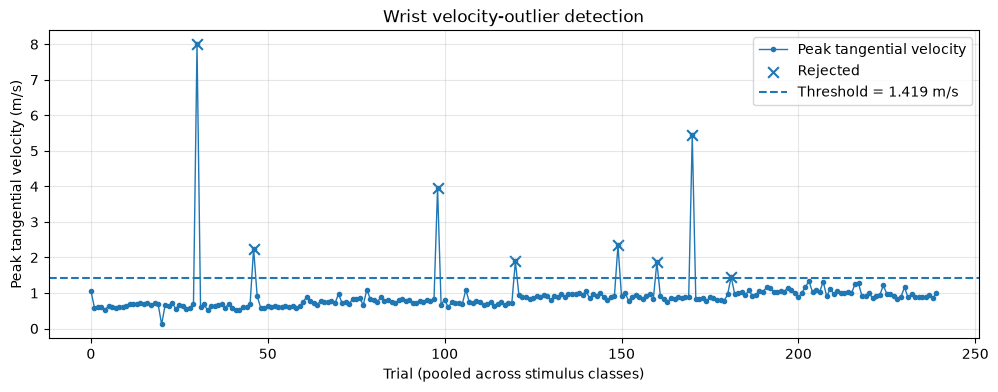

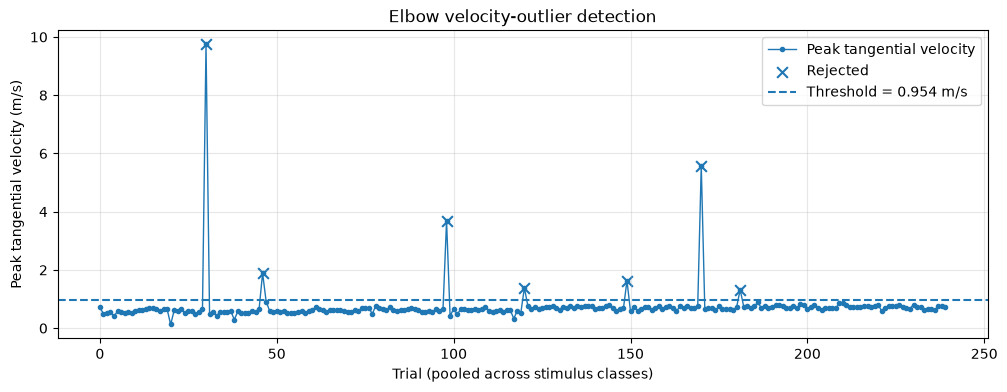

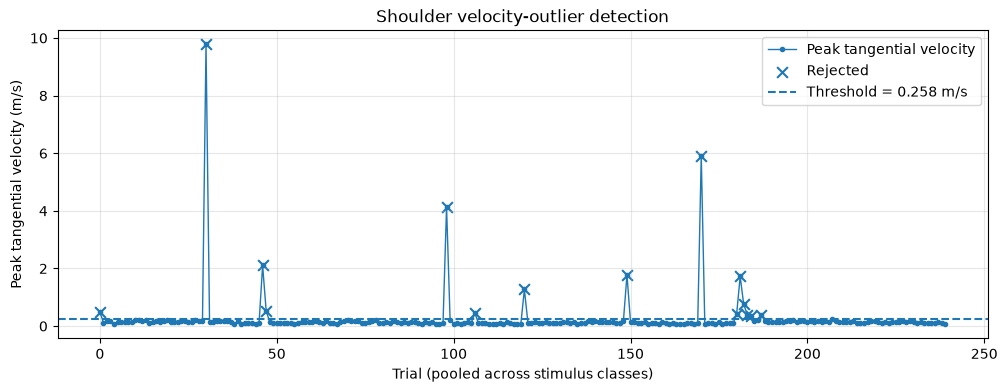


Rejected trials only:
Number 4   trial   0 | W=1.068 m/s, E=0.720 m/s, S=0.493 m/s | shoulder 0.49>0.26
Number 4   trial  30 | W=7.992 m/s, E=9.741 m/s, S=9.775 m/s | wrist 7.99>1.42; elbow 9.74>0.95; shoulder 9.77>0.26
Number 4   trial  46 | W=2.248 m/s, E=1.890 m/s, S=2.104 m/s | wrist 2.25>1.42; elbow 1.89>0.95; shoulder 2.10>0.26
Number 4   trial  47 | W=0.920 m/s, E=0.914 m/s, S=0.539 m/s | shoulder 0.54>0.26
Number 3   trial  38 | W=3.966 m/s, E=3.682 m/s, S=4.137 m/s | wrist 3.97>1.42; elbow 3.68>0.95; shoulder 4.14>0.26
Number 3   trial  46 | W=1.091 m/s, E=0.663 m/s, S=0.457 m/s | shoulder 0.46>0.26
Number 2   trial   0 | W=1.892 m/s, E=1.385 m/s, S=1.271 m/s | wrist 1.89>1.42; elbow 1.38>0.95; shoulder 1.27>0.26
Number 2   trial  29 | W=2.343 m/s, E=1.631 m/s, S=1.777 m/s | wrist 2.34>1.42; elbow 1.63>0.95; shoulder 1.78>0.26
Number 2   trial  40 | W=1.869 m/s, E=0.724 m/s, S=0.104 m/s | wrist 1.87>1.42
Number 2   trial  50 | W=5.442 m/s, E=5.583 m/s, S=5.906 m/s | wrist 5.4

In [412]:
# ============================================================
# Diagnostic plots: peak tangential velocity per trial
# Red markers = rejected trials
# Dashed line = robust joint-specific threshold
# ============================================================

def plot_joint_peak_qc(peaks, records, threshold, joint_name):
    x = np.arange(len(peaks))
    rejected = peaks > threshold

    plt.figure(figsize=(12, 4))
    plt.plot(x, peaks, '.-', linewidth=1, label='Peak tangential velocity')
    plt.scatter(x[rejected], peaks[rejected], marker='x', s=60,
                label='Rejected')
    plt.axhline(threshold, linestyle='--', linewidth=1.5,
                label=f'Threshold = {threshold:.3f} m/s')
    plt.xlabel('Trial (pooled across stimulus classes)')
    plt.ylabel('Peak tangential velocity (m/s)')
    plt.title(f'{joint_name.capitalize()} velocity-outlier detection')
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()


plot_joint_peak_qc(
    wrist_peaks, wrist_records, wrist_stats['threshold'], 'wrist'
)
plot_joint_peak_qc(
    elbow_peaks, elbow_records, elbow_stats['threshold'], 'elbow'
)
plot_joint_peak_qc(
    shoulder_peaks, shoulder_records, shoulder_stats['threshold'], 'shoulder'
)

# Optional: print only rejected trials in a compact table-like form
print('\nRejected trials only:')
for r in velocity_qc_results:
    if r['reject']:
        print(
            f"{r['class_name']:10s} trial {r['trial_index']:3d} | "
            f"W={r['wrist_peak']:.3f} m/s, E={r['elbow_peak']:.3f} m/s, "
            f"S={r['shoulder_peak']:.3f} m/s | "
            + '; '.join(r['reasons'])
        )


In [413]:
# Rejection reason summary
from collections import Counter

reason_counter = Counter()
for r in velocity_qc_results:
    if r['reject_wrist']:
        reason_counter['wrist velocity outlier'] += 1
    if r['reject_elbow']:
        reason_counter['elbow velocity outlier'] += 1
    if r['reject_shoulder']:
        reason_counter['shoulder velocity outlier'] += 1

print('Rejection reasons:')
for reason, count in reason_counter.items():
    print(f'  {reason}: {count}')

print(f'\nUnique rejected trials: {len(reject_label_index)}')


Rejection reasons:
  shoulder velocity outlier: 15
  wrist velocity outlier: 8
  elbow velocity outlier: 7

Unique rejected trials: 16


In [414]:
# reject label_index 
traject_wirst_label_cleaned = {}
traject_elbow_label_cleaned = {}
traject_shoulder_label_cleaned = {}
traject_IMU_label_cleaned = {}

for key in traject_wirst_label.keys():
    trials_wirst = []
    trials_elbow = []
    trials_shoulder = []
    trials_IMU = []
    for i in range(traject_wirst_label[key].shape[0]):
        if (key, i) not in reject_label_index:
            trials_wirst.append(traject_wirst_label[key][i])
            trials_elbow.append(traject_elbow_label[key][i])
            trials_shoulder.append(traject_shoulder_label[key][i])
            trials_IMU.append(traject_IMU_label[key][i])
        else:
            print("Removing trial index:", i, "from class:", key)
    traject_wirst_label_cleaned[key] = np.stack(trials_wirst, axis=0)
    traject_elbow_label_cleaned[key] = np.stack(trials_elbow, axis=0)
    traject_shoulder_label_cleaned[key] = np.stack(trials_shoulder, axis=0)
    traject_IMU_label_cleaned[key] = np.stack(trials_IMU, axis=0)


all_trajectory_ME = {}
all_trajectory_ME['shoulder'] = traject_shoulder_label_cleaned
all_trajectory_ME['elbow'] = traject_elbow_label_cleaned
all_trajectory_ME['wirst'] = traject_wirst_label_cleaned
all_trajectory_ME['IMU'] = traject_IMU_label_cleaned

import pickle
# save cleaned trajectory data
with open(f"D:\\MTP_task\\cam_data\\trajectory_label\\Trajectory_{subject}_ME.pkl", "wb") as f:
    pickle.dump(all_trajectory_ME, f)

# save reject label index
with open(f"D:\\MTP_task\\cam_data\\trajectory_label\\Reject_Labels_{subject}_ME.pkl", "wb") as f:
    pickle.dump(reject_label_index, f)

Removing trial index: 0 from class: Number 4
Removing trial index: 30 from class: Number 4
Removing trial index: 46 from class: Number 4
Removing trial index: 47 from class: Number 4
Removing trial index: 38 from class: Number 3
Removing trial index: 46 from class: Number 3
Removing trial index: 0 from class: Number 2
Removing trial index: 29 from class: Number 2
Removing trial index: 40 from class: Number 2
Removing trial index: 50 from class: Number 2
Removing trial index: 0 from class: Number 1
Removing trial index: 1 from class: Number 1
Removing trial index: 2 from class: Number 1
Removing trial index: 3 from class: Number 1
Removing trial index: 4 from class: Number 1
Removing trial index: 7 from class: Number 1


In [415]:
print(all_trajectory_ME['IMU']['Number 1'].shape)
print(all_trajectory_ME['IMU']['Number 2'].shape)
print(all_trajectory_ME['IMU']['Number 3'].shape)
print(all_trajectory_ME['IMU']['Number 4'].shape)

(54, 150, 6)
(56, 150, 6)
(58, 150, 6)
(56, 150, 6)


In [416]:
print(all_trajectory_ME['wirst']['Number 1'].shape)
print(all_trajectory_ME['wirst']['Number 2'].shape)
print(all_trajectory_ME['wirst']['Number 3'].shape)
print(all_trajectory_ME['wirst']['Number 4'].shape)

(54, 150, 3)
(56, 150, 3)
(58, 150, 3)
(56, 150, 3)


In [417]:
traject_shoulder_label_cleaned['Number 1'].shape

(54, 150, 3)

In [418]:
traject_IMU_label_cleaned['Number 1'].shape

(54, 150, 6)

# Average Trials for MI sessions

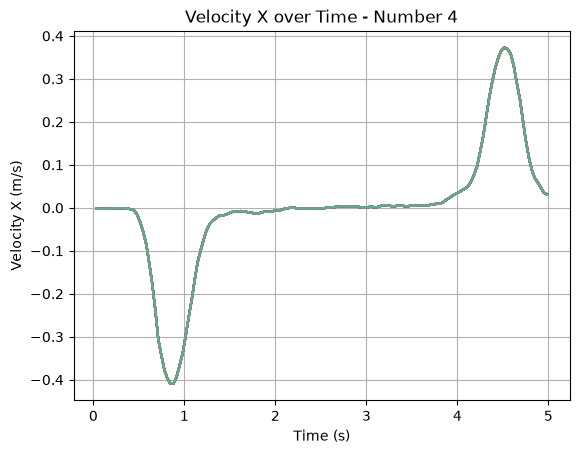

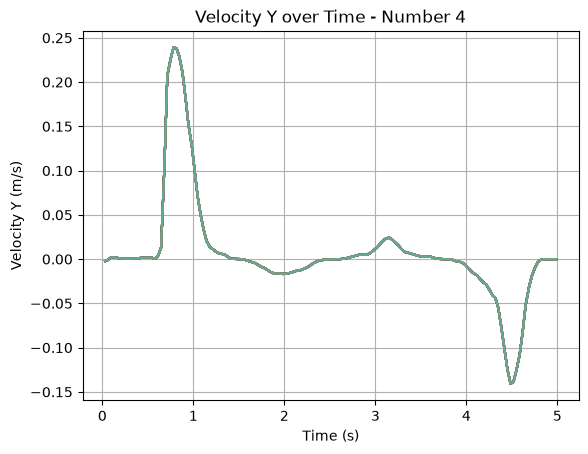

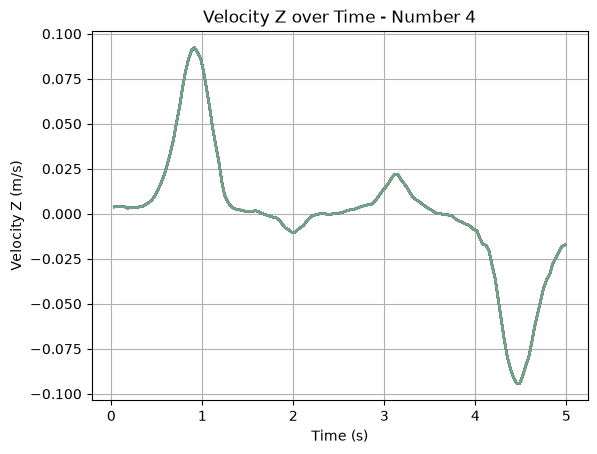

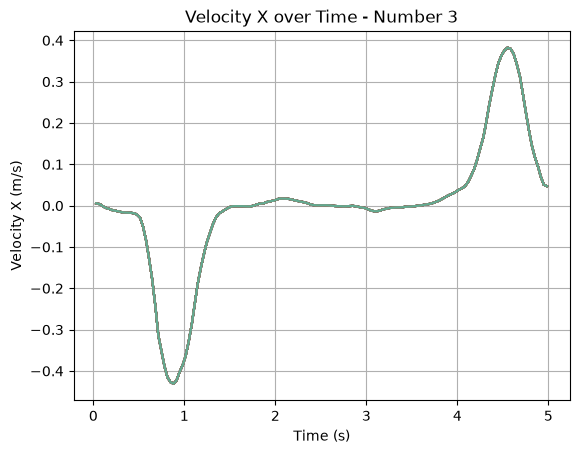

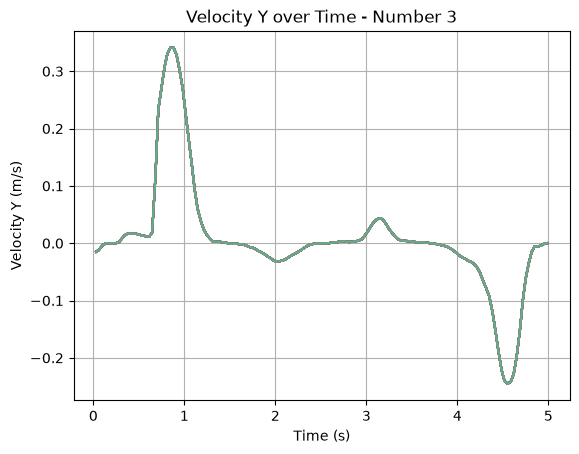

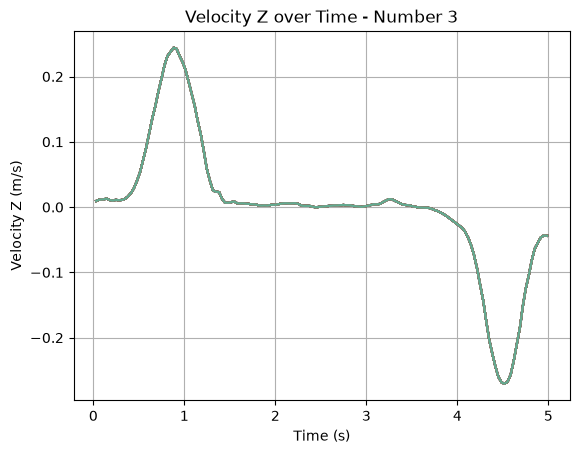

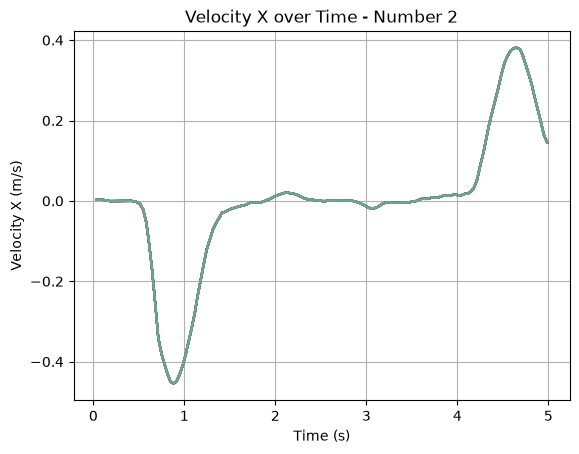

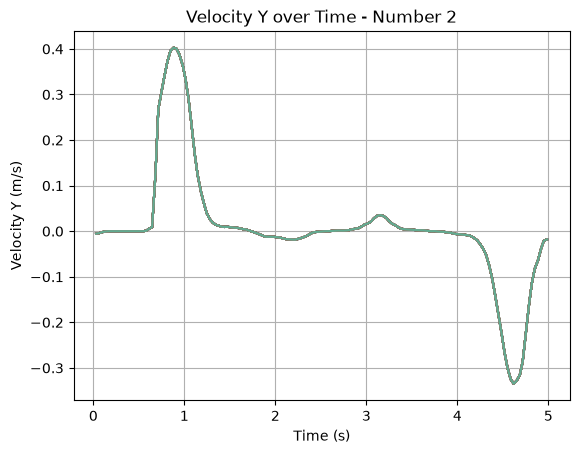

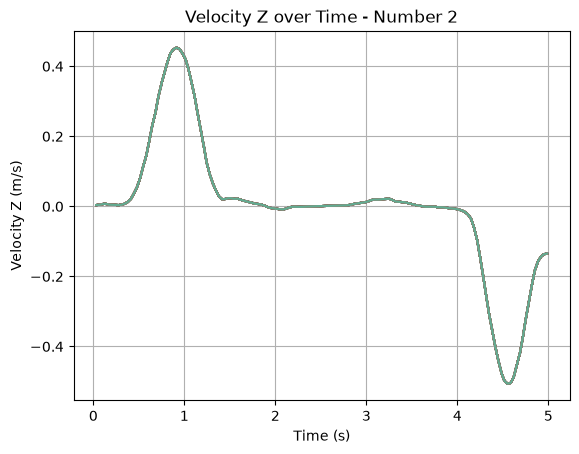

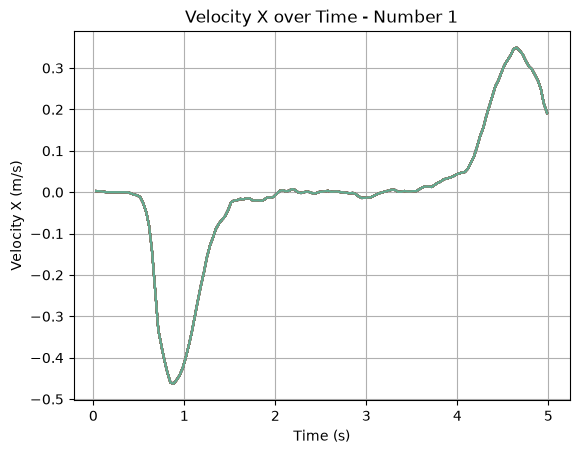

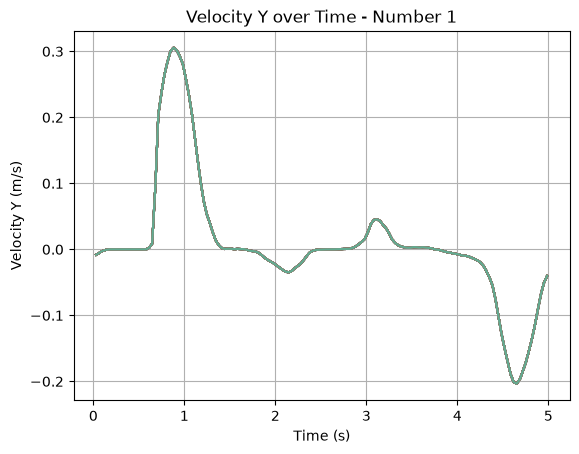

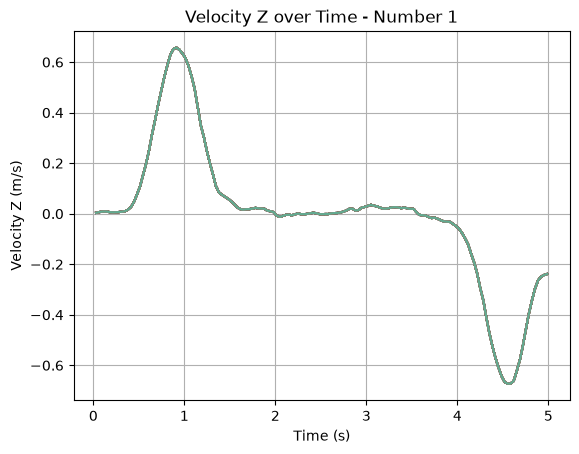

In [419]:
# Replace all trials with the class average trajectory
for class_name, vel_array in traject_shoulder_label_cleaned.items():
    avg_traj = np.mean(vel_array, axis=0)  # shape: (n_timepoints, 3)
    traject_shoulder_label_cleaned[class_name] = np.tile(avg_traj, (traject_shoulder_label['Number 1'].shape[0], 1, 1))

for class_name, vel_array in traject_elbow_label_cleaned.items():
    avg_traj = np.mean(vel_array, axis=0)  # shape: (n_timepoints, 3)
    traject_elbow_label_cleaned[class_name] = np.tile(avg_traj, (traject_elbow_label['Number 1'].shape[0], 1, 1))

for class_name, vel_array in traject_wirst_label_cleaned.items():
    avg_traj = np.mean(vel_array, axis=0)  # shape: (n_timepoints, 3)
    traject_wirst_label_cleaned[class_name] = np.tile(avg_traj, (traject_wirst_label['Number 1'].shape[0], 1, 1))

for class_name, vel_array in traject_IMU_label_cleaned.items():
    avg_traj = np.mean(vel_array, axis=0)  # shape: (n_timepoints, 3)
    traject_IMU_label_cleaned[class_name] = np.tile(avg_traj, (traject_IMU_label['Number 1'].shape[0], 1, 1))
    
all_trajectory_MI = {}
all_trajectory_MI['shoulder'] = traject_shoulder_label_cleaned
all_trajectory_MI['elbow'] = traject_elbow_label_cleaned
all_trajectory_MI['wirst'] = traject_wirst_label_cleaned
all_trajectory_MI['IMU'] = traject_IMU_label_cleaned

with open(f"D:\\MTP_task\\cam_data\\trajectory_label\\Trajectory_{subject}_MI.pkl", "wb") as f:
    pickle.dump(all_trajectory_MI, f)


# Plot Velocity X vs Time for each class
for class_name, vel_array in traject_wirst_label_cleaned.items():
    plt.figure()
    for trial in vel_array:
        plt.plot(t, trial[:, 0], alpha=0.5)
    plt.title(f"Velocity X over Time - {class_name}")
    plt.xlabel('Time (s)')
    plt.ylabel('Velocity X (m/s)')
    plt.grid(True)

    plt.figure()
    for trial in vel_array:
        plt.plot(t, trial[:, 1], alpha=0.5)
    plt.title(f"Velocity Y over Time - {class_name}")
    plt.xlabel('Time (s)')
    plt.ylabel('Velocity Y (m/s)')
    plt.grid(True)

    plt.figure()
    for trial in vel_array:
        plt.plot(t, trial[:, 2], alpha=0.5)
    plt.title(f"Velocity Z over Time - {class_name}")
    plt.xlabel('Time (s)')
    plt.ylabel('Velocity Z (m/s)')
    plt.grid(True)

plt.show()

In [420]:
all_trajectory_MI['IMU']

{'Number 4': array([[[-8.54884107e-03, -7.75893022e-03, -2.19581100e-02,
           8.65507670e-03, -6.90096847e-03, -2.28073490e-02],
         [-1.47227033e-02, -2.23615510e-04, -1.21625360e-02,
           9.85612364e-03,  1.14773988e-02, -1.79281640e-02],
         [-2.02289762e-02,  7.07065081e-03, -7.07359338e-04,
           9.67029655e-03,  2.74050302e-02, -1.17683948e-02],
         ...,
         [-1.14484914e-01,  1.60829558e-01,  1.99852935e-01,
          -1.07755363e-01,  2.64050835e-01,  1.16356497e-01],
         [-9.63537021e-02,  1.14834131e-01,  1.29563420e-01,
          -9.69392902e-02,  2.32397596e-01,  7.13870628e-02],
         [-7.80222939e-02,  7.01771913e-02,  6.13290642e-02,
          -8.83624605e-02,  2.02452785e-01,  2.95592775e-02]],
 
        [[-8.54884107e-03, -7.75893022e-03, -2.19581100e-02,
           8.65507670e-03, -6.90096847e-03, -2.28073490e-02],
         [-1.47227033e-02, -2.23615510e-04, -1.21625360e-02,
           9.85612364e-03,  1.14773988e-02, -1.79